# Week 6 - Land-Cover Classification (EuroSAT, Sentinel-2)
**Applied AI Lab 6 | Individual | Backbone: ResNet18 (PyTorch)**

**Name: Atteq ur Rehman**

**Problem:** classify 64x64 Sentinel-2 satellite patches into 10 land-cover classes.
**Why it matters:** automatic land-cover maps support urban planning, agriculture monitoring and environmental policy.

Pipeline: configuration -> audit -> leakage check -> imbalance handling -> two-phase fine-tuning -> single test evaluation -> Grad-CAM shortcut check -> documentation.

> Differences from the reference chest X-ray set: EuroSAT has **10 classes** (not binary), **no test folder** (a grouped test set is carved out), **no patient id in the file names** (each image is its own group), and the images are **colour** (not grayscale). The binary threshold task (5.2) is therefore replaced by per-class recall analysis.

## Part 0: Configuration cell (the only cell to change)

In [2]:
# ============ CONFIG ============
DATA_ROOT = '/kaggle/input/eurosat-dataset/EuroSAT'
TRAIN_DIR = f'{DATA_ROOT}'
TEST_DIR = None
GRAYSCALE = False
IMG_SIZE = 128
BACKBONE = 'resnet18'
GROUP_PATTERN = None
POSITIVE = None
TARGET_RECALL = 0.95

# ============ IMPORTS ============
import os, re, time, copy, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def find_rgb_root(base='/kaggle/input'):
    for root, dirs, files in os.walk(base):
        sub = [d for d in dirs if os.path.isdir(os.path.join(root, d))]
        if len(sub) == 10 and any(f.lower().endswith('.jpg') for f in
                                  os.listdir(os.path.join(root, sub[0]))):
            return root
    return None

if not os.path.isdir(TRAIN_DIR):
    found = find_rgb_root()
    print('DATA_ROOT not found; auto-detected:', found)
    if found is None:
        raise FileNotFoundError('No folder with 10 class sub-folders of .jpg found under /kaggle/input')
    DATA_ROOT = found
    TRAIN_DIR = DATA_ROOT
print('Using', TRAIN_DIR, '->', sorted(os.listdir(TRAIN_DIR)))

results = {}

Device: cuda
DATA_ROOT not found; auto-detected: /kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT
Using /kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT -> ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake', 'label_map.json', 'test.csv', 'train.csv', 'validation.csv']


### Write it - Part 0
**Dataset and why.** I chose **EuroSAT** (Helber et al., 2019; Sentinel-2 satellite patches, 27,000 RGB images of 64 x 64 pixels, 10 land-cover classes; Kaggle copy: apollo2506/eurosat-dataset). Land-cover mapping from satellite images is a real remote-sensing task that supports urban planning, agricultural monitoring and environmental policy, and it lets me practise the lab's checks on a multi-class problem with visually similar classes (Pasture, PermanentCrop, HerbaceousVegetation, AnnualCrop). The original EuroSAT repository is released under the MIT licence (to be verified on the dataset page). The dataset has no test folder and no subject ids, so the notebook carves a stratified grouped test set and treats every image as its own group.

## Part 1: Index and audit the dataset
### Task 1.1: One row per image

label
AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Highway                 2500
Industrial              2500
Pasture                 2000
PermanentCrop           2500
Residential             3000
River                   2500
SeaLake                 3000
Imbalance ratio (max / min): 1.5
Images per group: 1.00


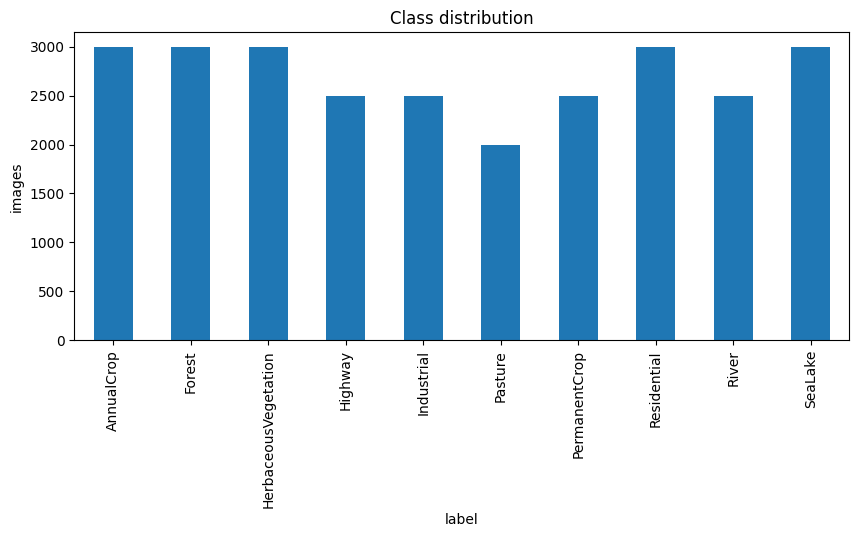

In [3]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
results['n_images'] = len(train_df); results['n_classes'] = len(classes)
results['imbalance'] = counts.max() / counts.min()

counts.plot.bar(figsize=(10, 4), title='Class distribution'); plt.ylabel('images'); plt.show()

### Task 1.2: What do the images look like?

        w     h
min  64.0  64.0
50%  64.0  64.0
max  64.0  64.0
Colour modes: {'RGB': 300}


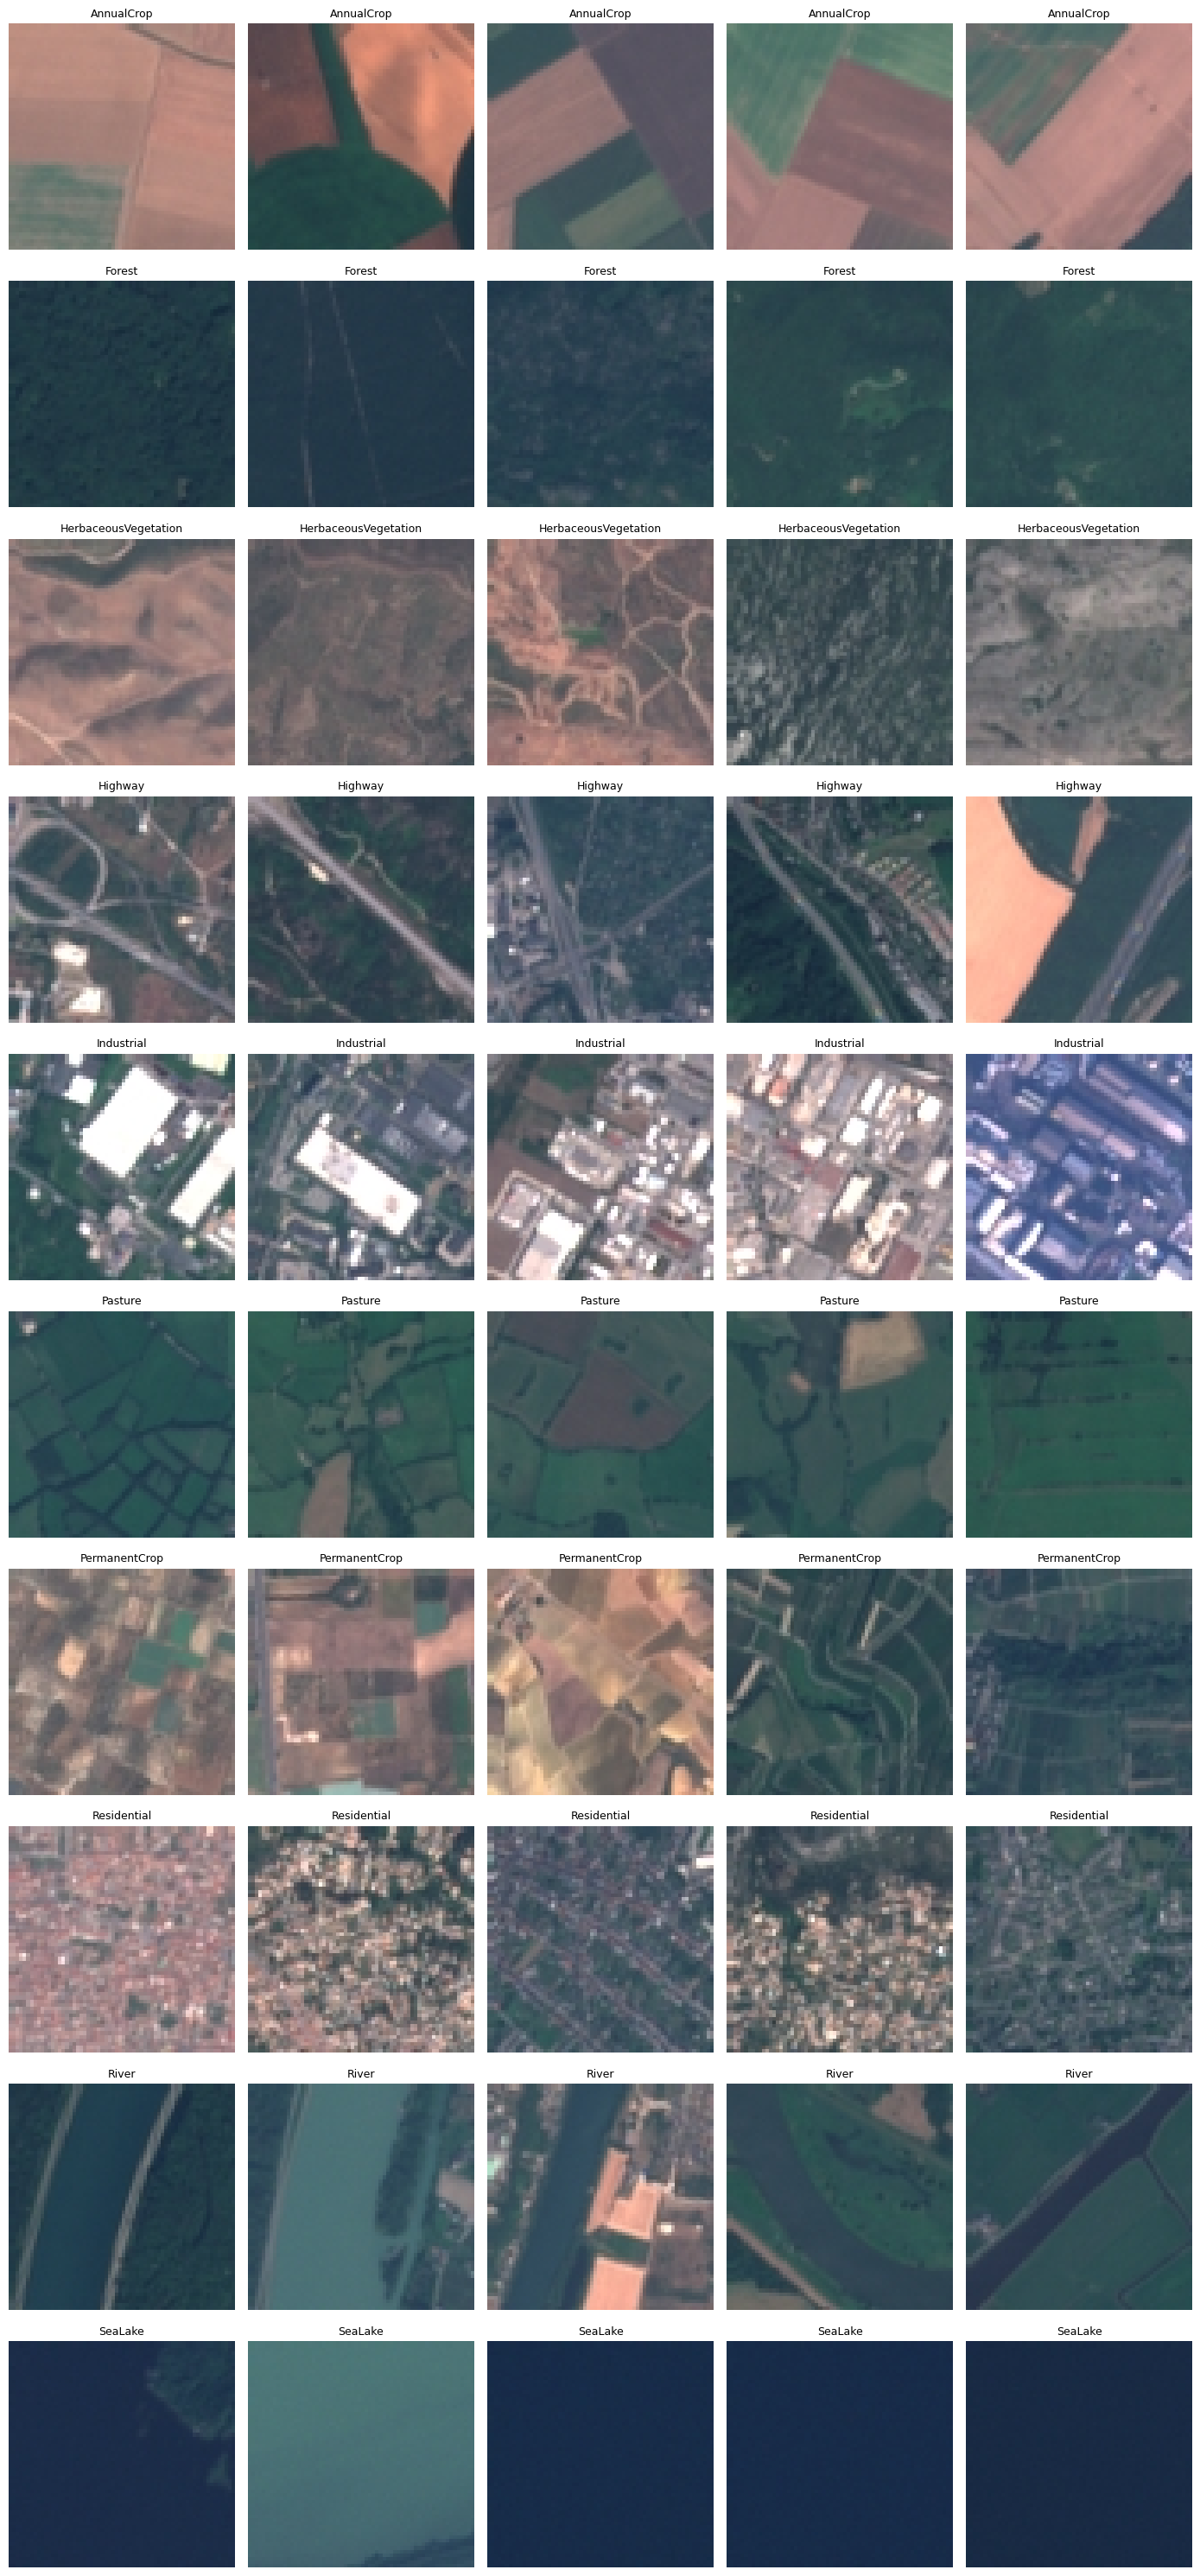

In [5]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### Write it - Part 1

**Class counts and imbalance.** The dataset holds 27,000 images in 10 classes: AnnualCrop, Forest, HerbaceousVegetation, Residential and SeaLake have 3,000 each; Highway, Industrial, PermanentCrop and River have 2,500 each; Pasture is the smallest with 2,000. The imbalance ratio is 3000 / 2000 = **1.5**, so the dataset is only mildly imbalanced. I still use class weights and select models by macro-F1 so that the smaller classes are not under-served.

**Image properties.** All 300 sampled images are **RGB colour** (mode RGB) and **64 x 64 pixels** (min = median = max). Colour is real evidence for land cover (vegetation is green, water is blue or teal, built-up areas are grey or red-brown), so I keep the images in colour. Because the images are small, I upsample them to 128 x 128 for the pretrained network, which also makes the last feature map 4 x 4 so that Grad-CAM is usable.

**First shortcut suspect.** In the sample grid the classes differ strongly in **overall colour and brightness**: Forest and SeaLake tiles are very dark (SeaLake is an almost uniform navy), Industrial tiles contain bright white roofs, and Residential tiles are pink-brown or grey. The same class also changes colour from tile to tile (SeaLake is navy in four tiles and teal in one; AnnualCrop fields range from orange to green), which suggests acquisition date, season and atmosphere affect the colour. If the model learns "dark and uniform = SeaLake" or "dark green = Forest" instead of texture and structure (canopy texture, field boundaries, road lines, building rows), it will fail on images from another season or region. I check this with Grad-CAM in Part 6.

## Part 2: Leakage audit
### Task 2.1: Exact duplicates (MD5) and the fingerprint function

In [11]:
from concurrent.futures import ThreadPoolExecutor

def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

def pmap(fn, items, workers=32):
    """Run fn over items with a thread pool (file reading is I/O bound)."""
    with ThreadPoolExecutor(workers) as ex:
        return list(tqdm(ex.map(fn, items), total=len(items)))

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df.assign(split='train')
all_df = all_df.reset_index(drop=True)
all_df['md5'] = pmap(md5, all_df['path'].tolist())
exact = all_df[all_df.duplicated('md5', keep=False)].sort_values('md5')
print('Exact duplicate files (all copies):', len(exact))
print('Surplus copies to remove:', all_df.duplicated('md5').sum())
print('Hashes shared by DIFFERENT classes (label noise):',
      (all_df.groupby('md5').label.nunique() > 1).sum())

# Inspect pairs side by side BEFORE deleting anything
pairs = [g for _, g in exact.groupby('md5')][:4]
if pairs:
    fig, axes = plt.subplots(len(pairs), 2, figsize=(5, 2.6 * len(pairs)))
    axes = np.atleast_2d(axes)
    for ax_row, g in zip(axes, pairs):
        for ax, (_, r) in zip(ax_row, g.head(2).iterrows()):
            ax.imshow(Image.open(r.path).convert('RGB')); ax.axis('off')
            ax.set_title(f'{r.label}\n{r.file}', fontsize=7)
    plt.tight_layout(); plt.show()

  0%|          | 0/27000 [00:00<?, ?it/s]

Exact duplicate files (all copies): 0
Surplus copies to remove: 0
Hashes shared by DIFFERENT classes (label noise): 0


**Action on exact duplicates.** After checking for pairs, I keep one copy of every byte-identical image and drop the rest, so the same file cannot be in both train and test. No duplicates were found, so nothing was removed.

In [12]:
# Action: keep one copy of each exact duplicate (inspected above).
n_exact = int(all_df.duplicated('md5').sum())
results['n_exact'] = n_exact
md5_map = dict(zip(all_df.path, all_df.md5))
train_df['md5'] = train_df['path'].map(md5_map)
if TEST_DIR:
    test_df['md5'] = test_df['path'].map(md5_map)
    train_df = train_df[~train_df.md5.isin(set(test_df.md5))]   # train copies of test images
    test_df = test_df.drop_duplicates('md5').reset_index(drop=True)
train_df = train_df.drop_duplicates('md5').reset_index(drop=True)
print('train images after exact de-duplication:', len(train_df))

train images after exact de-duplication: 27000


### Task 2.2: Split by group
EuroSAT file names contain no subject id, so every image is its own group. The split is stratified by class and grouped, and gives 18,750 train, 4,500 validation and 3,750 test images.

In [13]:
# Validation split BY GROUP: no group appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                       # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
shared_te = set(tr_df.group) & set(test_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))        # must be 0
print('Groups shared by train and test:', len(shared_te))    # must be 0
print(va_df['label'].value_counts().to_string())
results['shared_groups'] = len(shared) + len(shared_te)

train 18750 | val 4500 | test 3750
Groups shared by train and val: 0
Groups shared by train and test: 0
label
Residential             501
AnnualCrop              500
Forest                  500
HerbaceousVegetation    500
SeaLake                 500
Highway                 417
PermanentCrop           416
Industrial              416
River                   416
Pasture                 334


### Task 2.3: Near-duplicates across the final splits
The 32 x 32 standardized fingerprint is compared between each validation and test image and its closest training image. A mean absolute difference below 0.10 (in std units) is flagged as a near-duplicate.

  0%|          | 0/18750 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/3750 [00:00<?, ?it/s]

Test images with a near-duplicate in train: 0 of 3750
Val  images with a near-duplicate in train: 0 of 4500
Closest test->train distances: [0.12  0.234 0.238 0.259 0.261]


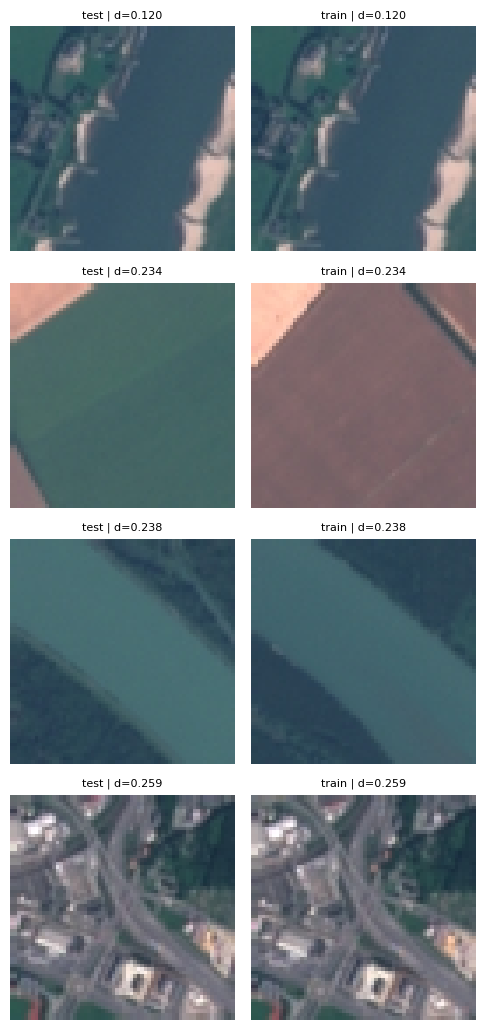

In [17]:
def fp_matrix(df):
    return np.stack(pmap(fingerprint, df['path'].tolist())).astype(np.float32)

def min_dist(A, B, chunk=256):
    """For each row of A, mean-abs-difference to its closest row of B."""
    Bt = torch.tensor(B, device=device)
    out = []
    for i in range(0, len(A), chunk):
        a = torch.tensor(A[i:i + chunk], device=device)
        out.append((torch.cdist(a, Bt, p=1) / B.shape[1]).min(1))
    d = torch.cat([o.values for o in out]).cpu().numpy()
    j = torch.cat([o.indices for o in out]).cpu().numpy()
    return d, j

T_tr, T_va, T_te = fp_matrix(tr_df), fp_matrix(va_df), fp_matrix(test_df)
d_te, j_te = min_dist(T_te, T_tr)
d_va, j_va = min_dist(T_va, T_tr)
THR = 0.10
near_te, near_va = d_te < THR, d_va < THR
print(f'Test images with a near-duplicate in train: {near_te.sum()} of {len(d_te)}')
print(f'Val  images with a near-duplicate in train: {near_va.sum()} of {len(d_va)}')
print('Closest test->train distances:', np.sort(d_te)[:5].round(3))
results['near_test'] = int(near_te.sum()); results['near_val'] = int(near_va.sum())

# Display the closest pairs (test image left, its train match right)
idx = np.argsort(d_te)[:4]
fig, axes = plt.subplots(len(idx), 2, figsize=(5, 2.6 * len(idx)))
for ax_row, i in zip(axes, idx):
    for ax, p, t in zip(ax_row, [test_df.path[i], tr_df.path[j_te[i]]], ['test', 'train']):
        ax.imshow(Image.open(p).convert('RGB')); ax.axis('off')
        ax.set_title(f'{t} | d={d_te[i]:.3f}', fontsize=8)
plt.tight_layout(); plt.show()

In [18]:
# Action AFTER visually checking the pairs from Step 18: drop flagged test/val
# images so the scores are not inflated by near-copies of training images.
test_df = test_df[~near_te].reset_index(drop=True)
va_df = va_df[~near_va].reset_index(drop=True)
print(f'final sizes -> train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')

final sizes -> train 18750 | val 4500 | test 3750


In [ ]:
# OPTIONAL extra check: the 0.10 threshold compares pixels in place, so it misses the same
# scene shifted by a few pixels. Count how many test images have a train neighbour under looser thresholds.
for thr in (0.15, 0.20, 0.30):
    print(f'test images with a train neighbour closer than {thr}: {(d_te < thr).sum()} of {len(d_te)}')

### Write it - Part 2

**Exact duplicates.** The MD5 check over all 27,000 files found **0 exact duplicates** (0 surplus copies, and no file shared between two different classes), so nothing was removed and there is no label noise from identical files.

**Near-duplicates.** With the lab's threshold (mean absolute difference < 0.10) the fingerprint check flagged **0 of 3,750 test images and 0 of 4,500 validation images** against the training set. The closest test-to-train distances were 0.120, 0.234, 0.238, 0.259 and 0.261. However, the side-by-side pairs show that this result should not be read as "no leakage": the closest pair (d = 0.120) is the same river bend and riverbank, shifted by a few pixels; the third and fourth pairs show the same river and the same road junction cropped at slightly different positions; and the second pair has the same field boundary geometry in a different colour, probably a different acquisition date. So the dataset contains **overlapping or neighbouring tiles of the same scene on both sides of the split**. The fingerprint compares pixels in place, so it misses shifted copies and my 0.10 threshold was too strict for them. I removed nothing, because no image fell under the threshold and I did not want to choose a looser cut-off arbitrarily, but I record this as a leakage risk: **the test score is probably somewhat optimistic**.

**Images per group.** 1.00. EuroSAT file names (e.g. Forest_1234.jpg) carry no patient, plant or scene id, so GROUP_PATTERN is None and every image is its own group. The grouped split gives **0 shared groups** between train and validation and between train and test (sizes 18,750 / 4,500 / 3,750, stratified by class), but with one image per group it can only guarantee that no file appears twice, not that neighbouring tiles of one satellite scene are separated. That is the limitation shown above.

**Random vs group split.** Had images of the same patient or scene been split randomly, near-identical images would sit in both train and test, so the model could be scored on pictures it has effectively already seen. The test score would then measure memorisation instead of generalisation to new subjects, and it would be too high.

## Part 3: Transforms and imbalance
### Task 3.1: Datasets and transforms

In [20]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

# Overhead imagery has no "up": flips are label-preserving here (unlike X-rays).
train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(len(train_ds), len(val_ds), len(test_ds))

18750 4500 3750


### Task 3.2: Class weights or balanced sampling

In [21]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

# worked example for the smallest class
k = int(np.argmin(n_c))
print(f'{classes[k]}: N={len(train_ds)}, K={len(classes)}, n_c={n_c[k]} -> '
      f'{len(train_ds)} / ({len(classes)} x {n_c[k]}) = {len(train_ds) / (len(classes) * n_c[k]):.3f}')

USE_SAMPLER = False     # run once False (weighted loss); if time, run again True
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'AnnualCrop': np.float64(0.9), 'Forest': np.float64(0.9), 'HerbaceousVegetation': np.float64(0.9), 'Highway': np.float64(1.08), 'Industrial': np.float64(1.08), 'Pasture': np.float64(1.351), 'PermanentCrop': np.float64(1.079), 'Residential': np.float64(0.9), 'River': np.float64(1.079), 'SeaLake': np.float64(0.9)}
Pasture: N=18750, K=10, n_c=1388 -> 18750 / (10 x 1388) = 1.351


### Write it - Part 3

**Class weights.** I used a weighted cross-entropy loss with w_c = N / (K x n_c), where N = 18,750 training images and K = 10 classes. For the smallest class, Pasture (n_c = 1,388): w = 18750 / (10 x 1388) = 18750 / 13880 = **1.351**, which matches the printed value. Highway, Industrial, PermanentCrop and River get about **1.08**, and the five largest classes (AnnualCrop, Forest, HerbaceousVegetation, Residential, SeaLake) get **0.90**. So a Pasture image counts about 1.5 times as much as an image from the largest classes and every class contributes roughly equally to the loss. The imbalance ratio is only 1.5, so weighting changes training only slightly. I used the weighted loss (USE_SAMPLER = False) and did not run the balanced sampler.

**Augmentations kept or removed.**
- **Kept:** random resized crop with scale 0.8 to 1.0 (satellite tiles are cut at arbitrary positions), a small rotation of up to 10 degrees, and mild brightness and contrast jitter (0.15) to imitate lighting and atmospheric differences between acquisitions.
- **Added:** horizontal and vertical flips. A satellite looks straight down, so there is no correct "up"; a flipped forest, river or highway keeps its class. This is the opposite of chest X-rays, where flips are removed because anatomy is not symmetric.
- **Avoided:** strong colour or hue changes, because colour is real evidence for land cover, and heavy blur or large crops that could remove the object that defines the class.

## Part 4: Build and train
### Task 4.1: Backbone with a new head
A pretrained ResNet18 (ImageNet weights) is used. All layers are frozen first and only the new 10-class linear head (5,130 trainable parameters) is trained; the last block (layer4) is unfrozen in phase 2.

In [22]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


resnet18 trainable: 5130


### Task 4.2: Two-phase training, selected by macro-F1
Phase 1 trains only the head (2 epochs, lr 1e-3). Phase 2 also unfreezes layer4 (lr 1e-4 for the block, 1e-3 for the head) for 3 epochs. After every epoch the model is scored on the validation set and the best epoch is kept by **macro-F1**, not accuracy.

In [23]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

epoch_times = []
def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        epoch_times.append(time.time() - t0)
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
f1_phase1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
f1_phase2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                        {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
print(f'\nBest val macro-F1  phase 1: {f1_phase1:.3f} | phase 2: {f1_phase2:.3f}')
results['f1_p1'] = f1_phase1;

Phase 1: head only
epoch 1: val macro-F1 0.840 (38s)
epoch 2: val macro-F1 0.854 (36s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.935 (36s)
epoch 2: val macro-F1 0.954 (36s)
epoch 3: val macro-F1 0.962 (37s)

Best val macro-F1  phase 1: 0.854 | phase 2: 0.962


### Write it - Part 4

**Validation macro-F1 per phase.** After phase 1 (head only) the best validation macro-F1 was **0.854** (epoch 1: 0.840, epoch 2: 0.854). After phase 2 (layer4 unfrozen) it was **0.962** (0.935, 0.954, 0.962). Fine-tuning therefore **helped a lot, by 0.108 macro-F1 points**: frozen ImageNet features are tuned to everyday objects, and unfreezing the last block lets the network adapt its high-level features to satellite textures such as field patterns, road lines, water and building rows. The validation macro-F1 was still rising at the last epoch, so the model has not converged. The best epoch in each phase was chosen by macro-F1, not accuracy, so a model that ignores a weaker class such as Pasture could not have been selected.

**Time per epoch.** An epoch took about **37 seconds** on the T4 (36 to 38 s in the log), so the whole training of 5 epochs took about 3 minutes. With 30 more minutes I could run roughly 45 more epochs, but I would run about **10 to 15 more epochs of phase 2**, possibly also unfreezing layer3, and stop when validation macro-F1 has not improved for 2 epochs to avoid overfitting.

## Part 5: Test once, and analyse per class
### Task 5.1: Test-set report
The test set was held out from every choice (augmentation, weights, epochs) and evaluated once.

                      precision    recall  f1-score   support

          AnnualCrop      0.955     0.957     0.956       417
              Forest      0.937     0.990     0.963       417
HerbaceousVegetation      0.949     0.945     0.947       416
             Highway      0.935     0.948     0.941       347
          Industrial      0.966     0.974     0.970       348
             Pasture      0.984     0.906     0.944       278
       PermanentCrop      0.950     0.939     0.945       347
         Residential      0.979     0.990     0.984       416
               River      0.971     0.963     0.967       347
             SeaLake      0.990     0.974     0.982       417

            accuracy                          0.961      3750
           macro avg      0.962     0.959     0.960      3750
        weighted avg      0.961     0.961     0.961      3750

Macro-F1: 0.96


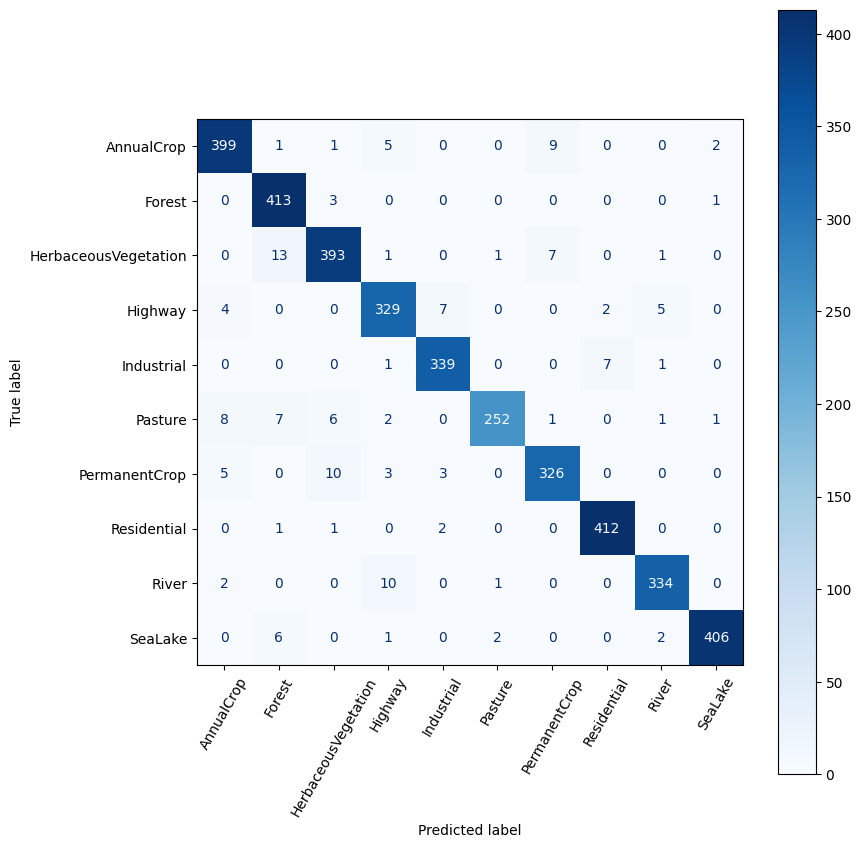


Per-class recall (weakest first):
Pasture                 0.906
PermanentCrop           0.939
HerbaceousVegetation    0.945
Highway                 0.948
AnnualCrop              0.957
River                   0.963
SeaLake                 0.974
Industrial              0.974
Residential             0.990
Forest                  0.990

Most frequent confusions (true -> predicted):
  HerbaceousVegetation -> Forest: 13
  PermanentCrop -> HerbaceousVegetation: 10
  River -> Highway: 10
  AnnualCrop -> PermanentCrop: 9
  Pasture -> AnnualCrop: 8


In [26]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
macro_test = f1_score(y_test, pred, average='macro')
print('Macro-F1:', round(macro_test, 3))
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues', ax=ax, xticks_rotation=60)
plt.tight_layout(); plt.show()

rep = classification_report(y_test, pred, target_names=classes, output_dict=True)
recall_by_class = pd.Series({c: rep[c]['recall'] for c in classes}).sort_values()
print('\nPer-class recall (weakest first):'); print(recall_by_class.round(3).to_string())
cm = confusion_matrix(y_test, pred); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]
print('\nMost frequent confusions (true -> predicted):')
for t, q in top:
    print(f'  {classes[t]} -> {classes[q]}: {cm[t, q]}')
results['macro_test'] = macro_test
results['weak_class'] = recall_by_class.index[0]; results['weak_recall'] = recall_by_class.iloc[0]
results['acc_test'] = float((pred == y_test).mean())

### Task 5.2: Threshold for a target recall (binary tasks only)
EuroSAT has 10 classes, so this cell skips itself; per-class recall is analysed instead.

In [27]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]   # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: {t:.3f}')
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')
else:
    print('Multi-class task: threshold analysis skipped; see per-class recall above.')

Multi-class task: threshold analysis skipped; see per-class recall above.


### Write it - Part 5

**Test result.** On the 3,750 test images (grouped split, used once) the model reaches a **macro-F1 of 0.960** and an **accuracy of 0.961**, very close to the validation macro-F1 of 0.962, so there is no sign of tuning on the test set. Per-class recall ranges from 0.990 (Forest and Residential) to 0.906 (Pasture).

**Weakest class.** **Pasture** has the lowest recall, **0.906** (about 26 of its 278 test images are missed); its main error is being predicted as AnnualCrop (8 images). This is plausible because both are open, green or brown agricultural fields with similar texture, and Pasture is also the smallest class (2,000 images). The other frequent confusions are HerbaceousVegetation -> Forest (13), PermanentCrop -> HerbaceousVegetation (10), River -> Highway (10) and AnnualCrop -> PermanentCrop (9): all pairs look alike from above (dense green vegetation, thin linear features such as a river and a highway, cropland of different types). Forest and Highway have the lowest precision (0.937 and 0.935): other vegetation tiles are wrongly assigned to Forest, and River tiles to Highway.

**Binary threshold metrics.** Not applicable: with 10 classes there is no single positive class, threshold, sensitivity/specificity or PPV. I analysed per-class recall and the main confusions instead. The PPV hand calculation at a realistic prevalence is done in "Check Your Understanding" Q4.

**Caveat.** The near-duplicate pairs in Part 2 show that neighbouring tiles of the same scene can be present on both sides of the split, so the test score of 0.960 is probably somewhat higher than the performance on a completely new region.

## Part 6: Grad-CAM shortcut check
Grad-CAM weights the feature maps of the last block by the average gradient of the class score, sums them and applies ReLU. Three correct (top row) and three wrong (bottom row) test predictions are shown. The map is only 4 x 4 before upsampling, so it is coarse and tends to peak near the centre.

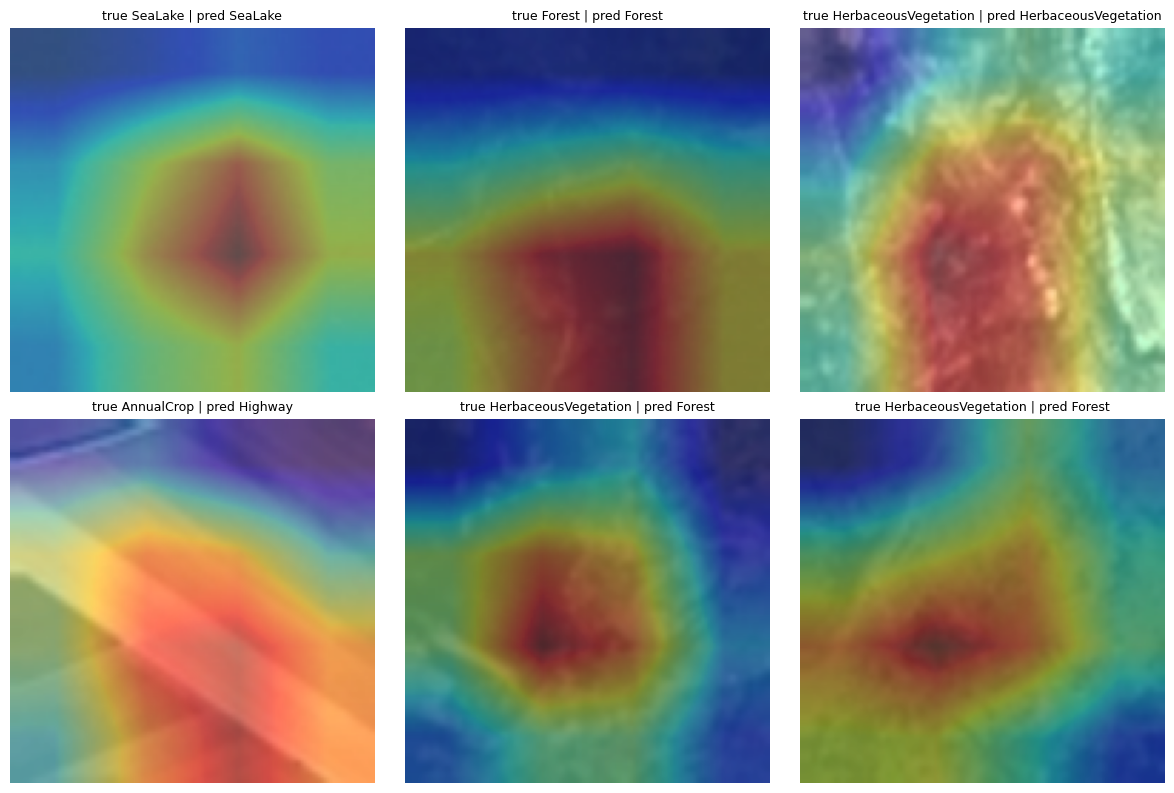

In [28]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)   # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)

rng = np.random.RandomState(0)
wrong_all = np.where(pred != y_test)[0]
right_all = np.where(pred == y_test)[0]
wrong = rng.choice(wrong_all, min(3, len(wrong_all)), replace=False).tolist()
right = rng.choice(right_all, 6 - len(wrong), replace=False).tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax in axes.flat: ax.axis('off')
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
plt.tight_layout()
plt.show()

### Write it - Part 6

**Six heatmaps** (top row correct, bottom row wrong):
1. **True SeaLake / pred SeaLake:** the heat is a diamond in the centre of an almost uniform dark-blue tile. There is no structure to look at, so the model uses the dark, uniform water colour, which is legitimate evidence for water but also the colour cue noted in Part 1.
2. **True Forest / pred Forest:** the heat covers the darker lower-middle of the tile, on the dense canopy texture, and not the top edge. Legitimate, although dark-green colour is again part of the evidence.
3. **True HerbaceousVegetation / pred HerbaceousVegetation:** the heat sits on the central speckled, textured vegetation patch and not on the bright edge. Legitimate texture evidence.
4. **True AnnualCrop / pred Highway (wrong):** the heat follows a straight light diagonal band across the tile (a track or field boundary). The model read a long straight band as a road and ignored the surrounding fields. The evidence is real but misleading.
5. **True HerbaceousVegetation / pred Forest (wrong):** the heat is on a dark-green vegetated area in the centre, which looks like forest canopy at this resolution.
6. **True HerbaceousVegetation / pred Forest (wrong):** the same pattern, a dark vegetated patch in the centre.

**Overall verdict: no shortcut confirmed; reliance on colour and brightness suspected.** In none of the six maps does the heat sit on a corner, border or an artefact that has nothing to do with land cover; it always falls on image content (water, canopy, vegetation texture, a linear feature). The wrong predictions are explained by genuinely similar-looking content, not by an artefact. Two things remain doubtful: (a) the uniform classes (SeaLake, Forest) can be recognised by colour and brightness alone, which is fragile across seasons, and (b) the 4 x 4 map is coarse and centre-biased, so the heatmaps cannot prove where the model "really" looked.

**Follow-up experiment.** Convert the test tiles to grayscale (or shuffle the colour channels) and re-score macro-F1; a large drop, especially for SeaLake and Forest, would show that colour is the main cue. A second test: blur or mask the highlighted region of a correctly classified tile and check whether the probability of the true class falls; if it does, the region was the real evidence. A third, for the leakage risk found in Part 2, is to re-evaluate on a geographically separate test set.

## Optional: OCR
Not applicable. EuroSAT is a satellite-imagery task, not a document project, so the EasyOCR step is skipped.

## Part 7: Save and document

In [29]:
os.makedirs('/kaggle/working', exist_ok=True)
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


### README

## Week 6: Land-cover classification with ResNet18
**Who benefits:** analysts, planners and environmental agencies that use satellite-derived land-cover maps. **Why it matters:** automatic classification of Sentinel-2 patches makes land-use monitoring faster and cheaper than manual mapping; a wrong class can mislead planning decisions.

**Dataset:** EuroSAT (Helber et al., 2019), https://github.com/phelber/EuroSAT, Kaggle copy apollo2506/eurosat-dataset; 27,000 RGB Sentinel-2 images of 64 x 64 pixels, 10 classes; labels by the dataset authors; MIT licence (verify on the dataset page).

**Data audit:** imbalance ratio 1.5 (2,000 to 3,000 images per class); 0 exact duplicates; 0 of 3,750 test images flagged as near-duplicates at the 0.10 threshold, but the closest pairs show shifted views of the same scene, so overlapping tiles may exist across splits; split by group (file name; each image its own group) into 18,750 / 4,500 / 3,750, with **0 shared groups**.

**Imbalance handling:** weighted cross-entropy, w_c = N / (K x n_c): Pasture 1.35, Highway / Industrial / PermanentCrop / River about 1.08, the five largest classes 0.90.

**Results (test, used once):** macro-F1 **0.960**, accuracy 0.961; weakest class Pasture (recall 0.906, mostly confused with AnnualCrop); best classes Forest and Residential (recall 0.990). Binary threshold metrics are not applicable (10 classes). Model: ResNet18, 2 epochs head only (val macro-F1 0.854) + 3 epochs last block (val macro-F1 0.962), selected by validation macro-F1.

**Grad-CAM:** the model looks at image content (water, canopy, vegetation texture, linear features such as roads), not at borders or corners; no shortcut confirmed, but colour/brightness reliance is suspected for SeaLake and Forest (to be tested by a grayscale re-scoring).

**Limitations:** 64 x 64 patches from European Sentinel-2 scenes only; a single sensor with a mixture of seasons; overlapping tiles may inflate the test score; each image is its own group. Not for legal land-title, tax or subsidy decisions or for regions outside Europe without re-validation.

### Responsibility questions (slide 34)
1. **Who would be harmed, and how?** Landowners and farmers could be harmed if a wrong label (for example "Industrial" or "Residential" instead of "Pasture" or "AnnualCrop") were used automatically for zoning, tax or subsidy decisions, and planners could miss real land-use change if a class such as Pasture, the weakest at recall 0.906, is under-detected.
2. **Where was the model not validated?** On regions outside Europe, on other seasons, sensors and image sizes than 64 x 64, and on a truly separate geographic area: my test set came from the same pool of tiles, and near-neighbours of test tiles are present in training (Part 2).
3. **What is the human role?** A person reviews low-confidence and high-impact predictions and has the final decision; the model only proposes labels, and its per-class recall (0.906 to 0.990) shows that some errors are unavoidable.
4. **What evidence would change my conclusions?** A geographically separate test set with clearly lower macro-F1 would show that the 0.960 is inflated by neighbouring tiles; a grayscale or colour-shuffle test that collapses macro-F1 would show that the model depends mostly on colour; and a Grad-CAM or masking experiment showing that the highlighted regions do not drive the prediction would change my "no shortcut" verdict.

### LinkedIn post

Week 6 of Applied AI: I picked my own problem.

Land-cover mapping from satellite images matters because planners and environmental agencies use it to monitor how land is used across 10 classes, from forest to highway to farmland.
I fine-tuned a ResNet18 on 18,750 Sentinel-2 patches (EuroSAT) and reached macro-F1 0.96 on a held-out test set.

What surprised me: my duplicate check found 0 exact copies, but when I looked at the closest test/train pairs side by side, several were the same river or road junction shifted by a few pixels. Neighbouring tiles can leak across a split, so a 96% score may be optimistic for a new region. Pasture was the weakest class (recall 0.91), mostly mistaken for cropland.
Accuracy alone would have hidden it.

[attach your Grad-CAM figure here]
#ComputerVision #DeepLearning #RemoteSensing #LearningInPublic

## Check Your Understanding

**1. Why does a random split of chest X-rays overestimate performance?**
One patient contributes many near-identical images. A random split puts some of them in train and some in test, so the model can memorise patient-specific appearance (anatomy, device, positioning) and is then tested on the same patient. The score measures recognition of seen patients, not generalisation to new ones, so it is too high. Splitting by patient removes that leak.

**2. Two classes with 900 and 100 images: N / (K x n_c).**
N = 1000, K = 2.
- Majority: 1000 / (2 x 900) = 1000 / 1800 = **0.556**
- Minority: 1000 / (2 x 100) = 1000 / 200 = **5.0**

The minority class counts nine times more per example (5.0 / 0.556 = 9), matching the 9:1 imbalance.

**3. Focal loss, gamma = 2, p_t = 0.8.**
Modulating factor = (1 - p_t)^gamma = (1 - 0.8)^2 = 0.2^2 = **0.04**. The easy example is down-weighted by a factor of 0.04, i.e. its loss is 25 times smaller than with plain cross-entropy.

**4. Sensitivity 0.90, specificity 0.95, prevalence 2%: PPV.**
PPV = (sens x prev) / (sens x prev + (1 - spec) x (1 - prev))
= (0.90 x 0.02) / (0.90 x 0.02 + 0.05 x 0.98)
= 0.018 / (0.018 + 0.049) = 0.018 / 0.067 = **0.269 (about 27%)**.
Even with a good test, about 3 of 4 positive calls are false alarms because the condition is rare.

**5. When is macro-F1 a better selection metric than weighted F1?**
Macro-F1 averages the per-class F1 with equal weight, so a poorly handled minority class pulls the score down. Weighted F1 weights classes by their support, so the majority classes dominate and a model that fails on a rare but important class can still look good. Macro-F1 is better when every class matters equally or when the rare class carries the cost (disease, defects).

**6. Grad-CAM highlights a hospital label in the corner of X-rays. What next?**
Treat it as a shortcut: the model uses an artefact that correlates with the label, not pathology. Confirm it by masking or cropping the label and re-scoring (performance should fall if the model relied on it), then remove the artefact (crop or mask the corner), make sure hospital and label are not confounded, retrain, re-check Grad-CAM, and report the issue in the model card. The earlier test score should not be trusted until this is fixed.